In [ ]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate dummy data
n_samples = 1000

data = {
    'Applicant_ID': range(1001, 1001 + n_samples),
    'Age': np.random.randint(18, 70, size=n_samples),
    'Annual_Income_USD': np.random.randint(20000, 150000, size=n_samples),
    'Credit_Score': np.random.randint(300, 850, size=n_samples),
    'Loan_Amount_USD': np.random.randint(5000, 100000, size=n_samples),
    'Gender': np.random.uniform(7.0, 9.0, size=n_samples).round(2)
}

df = pd.DataFrame(data)

# Determine loan approval based on simple logic: high credit score and income increase approval probability
# We also factor in the '7to9' column for illustrative purposes
score = (df['Credit_Score'] / 850) * 0.5 + (df['Annual_Income_USD'] / 150000) * 0.3 + (df['7to9'] / 9.0) * 0.2

df['Loan_Approved'] = np.where(score > 0.5, 'Approved', 'Rejected')

# Display the first few rows of the dummy dataset
print(f"Dataset Shape: {df.shape}")
print(df['Loan_Approved'].value_counts())
df.head()

NameError: name 'male' is not defined

### Dummy Loan Dataset Generation
We will create a structured dummy dataset specifically focusing on a '7to9' metric (e.g., a custom score scaled between 7.0 and 9.0) alongside other financial features, then determine a realistic distribution of approved and rejected loans.

In [ ]:
import pandas as pd
import numpy as np

# Set seed for reproducibility
np.random.seed(42)

# Generate 1,000 sample records
n_samples = 1000

data = {
    'Applicant_ID': [f'LP{i:04d}' for i in range(1, n_samples + 1)],
    'Age': np.random.randint(21, 65, size=n_samples),
    'Annual_Income_USD': np.random.randint(30000, 180000, size=n_samples),
    'Credit_Score': np.random.randint(400, 850, size=n_samples),
    'Debt_to_Income_Ratio': np.random.uniform(0.1, 0.6, size=n_samples).round(2),
    # The specific '7to9' column (representing an internal rating or risk factor metric)
    '7to9': np.random.uniform(7.0, 9.0, size=n_samples).round(2)
}

df_loans = pd.DataFrame(data)

# Simple deterministic approval rule where higher credit score, income, and '7to9' rating increase chances of approval
score = (
    (df_loans['Credit_Score'] - 400) / 450 * 0.4 +
    (df_loans['Annual_Income_USD'] / 180000) * 0.3 +
    (1 - df_loans['Debt_to_Income_Ratio']) * 0.1 +
    ((df_loans['7to9'] - 7.0) / 2.0) * 0.2
)

# Classify as Approved (1) or Rejected (0) based on target threshold
df_loans['Loan_Status'] = np.where(score >= 0.45, 'Approved', 'Rejected')

# Show dataset summary and first few records
print(df_loans['Loan_Status'].value_counts())
display(df_loans.head(10))

Loan_Status
Approved    707
Rejected    293
Name: count, dtype: int64


,Applicant_ID,Age,Annual_Income_USD,Credit_Score,Debt_to_Income_Ratio,7to9,Loan_Status
0,LP0001,59,165090,691,0.21,8.58,Approved
1,LP0002,49,41302,550,0.16,7.59,Rejected
2,LP0003,35,97506,513,0.13,8.08,Approved
3,LP0004,63,71157,636,0.23,7.69,Approved
4,LP0005,28,84917,465,0.12,7.83,Rejected
5,LP0006,41,126646,760,0.38,8.46,Approved
6,LP0007,59,113122,740,0.24,8.76,Approved
7,LP0008,39,54519,657,0.51,7.24,Rejected
8,LP0009,43,110910,648,0.14,8.27,Approved
9,LP0010,31,150430,848,0.21,8.16,Approved


### Logistic Regression on the Loan Dataset
Now we will prepare the dataset for a Logistic Regression model to predict `Loan_Status`. We will split the dataset, scale the numerical columns, train the model, and evaluate its performance.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# 1. Prepare features (X) and target (y)
# Drop ID and target columns for training features
feature_cols = ['Age', 'Annual_Income_USD', 'Credit_Score', 'Debt_to_Income_Ratio', '7to9']
X = df_loans[feature_cols]
y = df_loans['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

# 2. Split dataset into Training (80%) and Testing (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Scale features (essential for Logistic Regression coefficients interpretation)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train the Logistic Regression Model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Make predictions
y_pred = model.predict(X_test_scaled)

# 6. Evaluate Model
print("=== Model Evaluation ===")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.4f}\n")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

=== Model Evaluation ===
Accuracy Score: 0.9900

Confusion Matrix:
[[ 57   2]
 [  0 141]]

Classification Report:
              precision    recall  f1-score   support

    Rejected       1.00      0.97      0.98        59
    Approved       0.99      1.00      0.99       141

    accuracy                           0.99       200
   macro avg       0.99      0.98      0.99       200
weighted avg       0.99      0.99      0.99       200



In [ ]:
# Display feature importance / coefficients
coefficients = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("=== Feature Coefficients (Impact on Approval) ===")
display(coefficients)

=== Feature Coefficients (Impact on Approval) ===


,Feature,Coefficient
2,Credit_Score,5.763222
1,Annual_Income_USD,3.540493
4,7to9,3.017604
0,Age,-0.165107
3,Debt_to_Income_Ratio,-0.760358


### Bias and Variance Analysis (Learning Curve)
To evaluate bias and variance, we will plot the **Learning Curve**. This helps us determine if the model is underfitting (high bias - both training and validation scores are low) or overfitting (high variance - a large gap between training and validation scores).

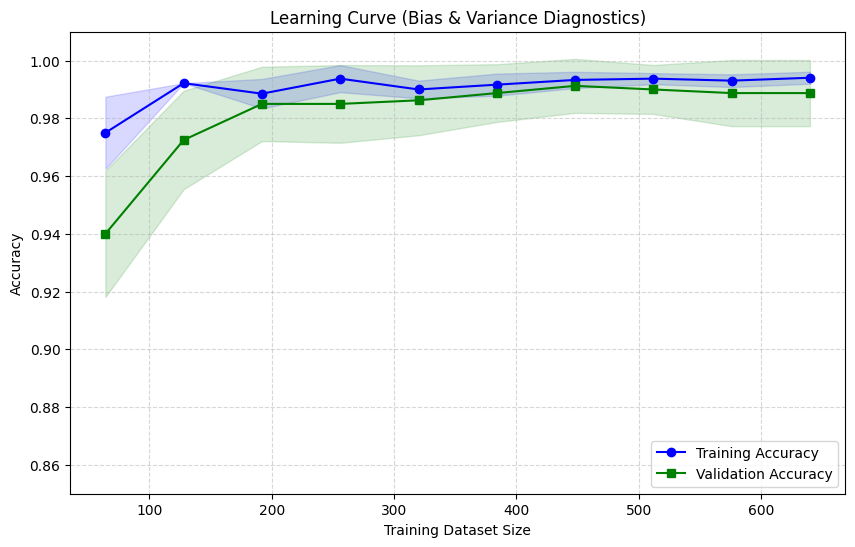

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Calculate learning curve values
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,
    X=X_train_scaled,
    y=y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10),
    random_state=42
)

# Calculate mean and standard deviation of train and test scores
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot the learning curve
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Accuracy')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')

plt.plot(train_sizes, test_mean, 's-', color='green', label='Validation Accuracy')
plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='green')

plt.title('Learning Curve (Bias & Variance Diagnostics)')
plt.xlabel('Training Dataset Size')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.ylim(0.85, 1.01)
plt.show()

### Classification Outcome Breakdown (Pie Chart)
To represent our results using a pie chart, we can look at the distribution of actual predictions compared to the ground truth on our test set. We will break down the predictions into **True Positives (TP)**, **True Negatives (TN)**, **False Positives (FP)**, and **False Negatives (FN)**.

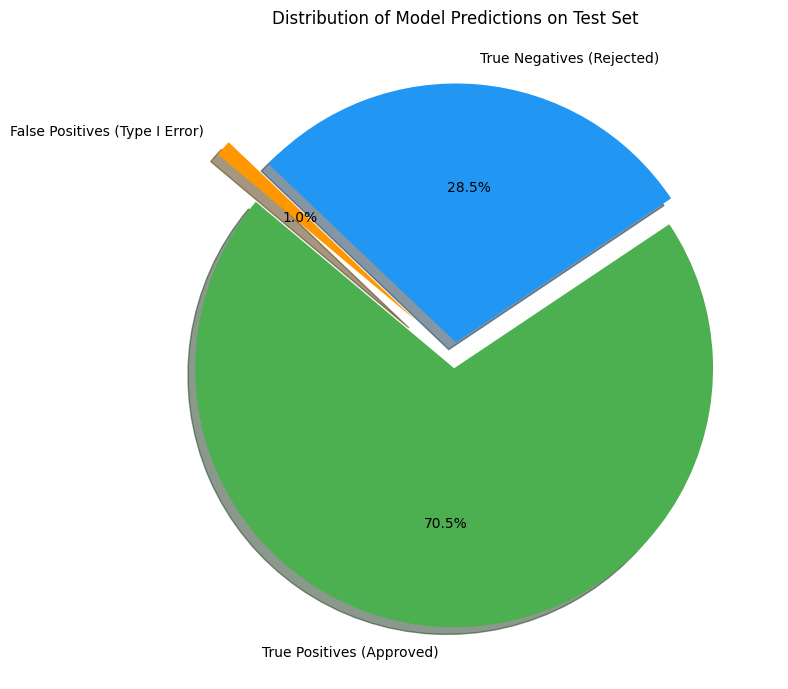

In [ ]:
import matplotlib.pyplot as plt

# Calculate True/False Positives/Negatives
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

labels = ['True Positives (Approved)', 'True Negatives (Rejected)', 'False Positives (Type I Error)', 'False Negatives (Type II Error)']
sizes = [tp, tn, fp, fn]
colors = ['#4CAF50', '#2196F3', '#FF9800', '#F44336']
explode = (0.05, 0.05, 0.2, 0.2)  # Explode smaller or error slices

# Filter out categories with 0 values to keep the chart clean
non_zero_labels = [labels[i] for i in range(len(sizes)) if sizes[i] > 0]
non_zero_sizes = [sizes[i] for i in range(len(sizes)) if sizes[i] > 0]
non_zero_colors = [colors[i] for i in range(len(sizes)) if sizes[i] > 0]
non_zero_explode = [explode[i] for i in range(len(sizes)) if sizes[i] > 0]

plt.figure(figsize=(8, 8))
plt.pie(
    non_zero_sizes,
    explode=non_zero_explode,
    labels=non_zero_labels,
    colors=non_zero_colors,
    autopct='%1.1f%%',
    shadow=True,
    startangle=140
)

plt.title('Distribution of Model Predictions on Test Set')
plt.tight_layout()
plt.show()

In [64]:
import pandas as pd

# Define custom applicant data
custom_applicant = {
    'Age': 45,
    'Annual_Income_USD': 85000,
    'Credit_Score': 680,
    'Debt_to_Income_Ratio': 0.35,
    '7to9': 8.2
}

# Convert to DataFrame to match feature names and structure
custom_df = pd.DataFrame([custom_applicant])

# Ensure correct feature ordering
X_custom = custom_df[feature_cols]

# Scale the features using the already fitted scaler
X_custom_scaled = scaler.transform(X_custom)

# Predict loan approval status and probability
prediction = model.predict(X_custom_scaled)[0]
probability = model.predict_proba(X_custom_scaled)[0]

# Map the prediction index to status string
status_mapping = {1: 'Approved', 0: 'Rejected'}
predicted_status = status_mapping[prediction]

print("=== Custom Applicant Evaluation ===")
for key, val in custom_applicant.items():
    print(f"{key}: {val}")
print("-" * 35)
print(f"Predicted Status: {predicted_status}")
print(f"Confidence (Approved): {probability[1]:.2%}")
print(f"Confidence (Rejected): {probability[0]:.2%}")

=== Custom Applicant Evaluation ===
Age: 45
Annual_Income_USD: 85000
Credit_Score: 680
Debt_to_Income_Ratio: 0.35
7to9: 8.2
-----------------------------------
Predicted Status: Approved
Confidence (Approved): 99.83%
Confidence (Rejected): 0.17%


### Test Model with Custom Input Fields
Use the form on the right to input custom applicant details, then run the cell to see the model's prediction.

In [70]:
import pandas as pd

# @title Custom Applicant Form (Drag Sliders to Test) { run: "auto" }
Age = 35 # @param {type:"slider", min:18, max:100, step:1}
Annual_Income_USD = 75000 # @param {type:"slider", min:10000, max:250000, step:5000}
Credit_Score = 690 # @param {type:"slider", min:300, max:850, step:10}
Debt_to_Income_Ratio = 0.6 # @param {type:"slider", min:0.0, max:1.0, step:0.05}
_7to9 = 7.6 # @param {type:"slider", min:7.0, max:9.0, step:0.1}

# Prepare input dictionary
custom_input = {
    'Age': Age,
    'Annual_Income_USD': Annual_Income_USD,
    'Credit_Score': Credit_Score,
    'Debt_to_Income_Ratio': Debt_to_Income_Ratio,
    '7to9': _7to9
}

# Convert to DataFrame
custom_df = pd.DataFrame([custom_input])
X_custom = custom_df[feature_cols]

# Scale and predict
X_custom_scaled = scaler.transform(X_custom)
prediction = model.predict(X_custom_scaled)[0]
probability = model.predict_proba(X_custom_scaled)[0]

# Display Results
predicted_status = 'Approved' if prediction == 1 else 'Rejected'
print("=== Evaluation Result ===")
print(f"Loan Status: {predicted_status}")
print(f"Confidence (Approved): {probability[1]:.2%}")
print(f"Confidence (Rejected): {probability[0]:.2%}")

=== Evaluation Result ===
Loan Status: Approved
Confidence (Approved): 83.98%
Confidence (Rejected): 16.02%
